# Draw this tree in five lines

A tree is a segment with two smaller trees on top. The code says exactly that.

In [1]:
import math
import matplotlib.pyplot as plt

def tree(ax, x, y, angle, length, depth):
    if depth == 0:                                       # base case
        return 0
    x2 = x + length * math.cos(math.radians(angle))
    y2 = y + length * math.sin(math.radians(angle))
    ax.plot([x, x2], [y, y2], color="#0a9086" if depth <= 2 else "#333", lw=max(0.5, depth * 0.6))
    calls = 1
    calls += tree(ax, x2, y2, angle - 25, length * 0.72, depth - 1)
    calls += tree(ax, x2, y2, angle + 25, length * 0.72, depth - 1)
    return calls

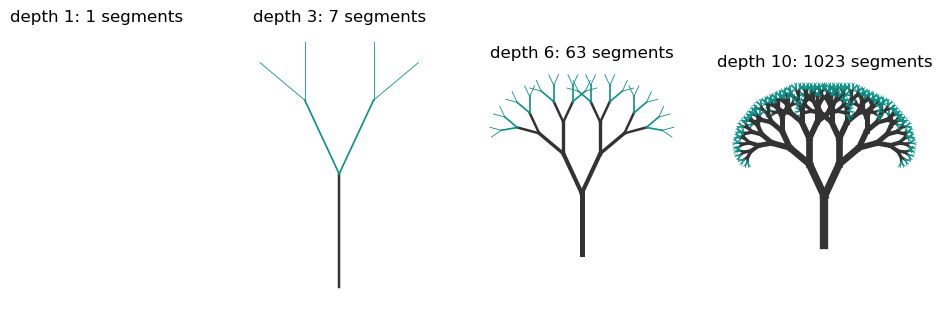

In [2]:
fig, axs = plt.subplots(1, 4, figsize=(12, 3.5))
for ax, d in zip(axs, [1, 3, 6, 10]):
    n = tree(ax, 0, 0, 90, 1.0, d)
    ax.set_title(f"depth {d}: {n} segments"); ax.set_aspect("equal"); ax.axis("off")
plt.show()

## Exponential work, linear depth

Every level doubles the number of segments ($2^{d}-1$ in total), but at any
moment only `depth` calls are waiting on the stack.

In [3]:
for d in [5, 10, 15, 20]:
    print(f"depth {d:2}: {2**d - 1:>9,} segments, {d:2} frames on the stack")

depth  5:        31 segments,  5 frames on the stack
depth 10:     1,023 segments, 10 frames on the stack
depth 15:    32,767 segments, 15 frames on the stack
depth 20: 1,048,575 segments, 20 frames on the stack


Change the two constants (25° and 0.72) and you get a different species; try
15° and 0.8.

**What we used:** base case and recursive case, tree recursion, the program stack
(session 6, sections 2, 4 and 7).